<a href="https://colab.research.google.com/github/Strangeabhi/ML-II-Abhishek_C_Patil-4NI23CI005/blob/main/KMeansClustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

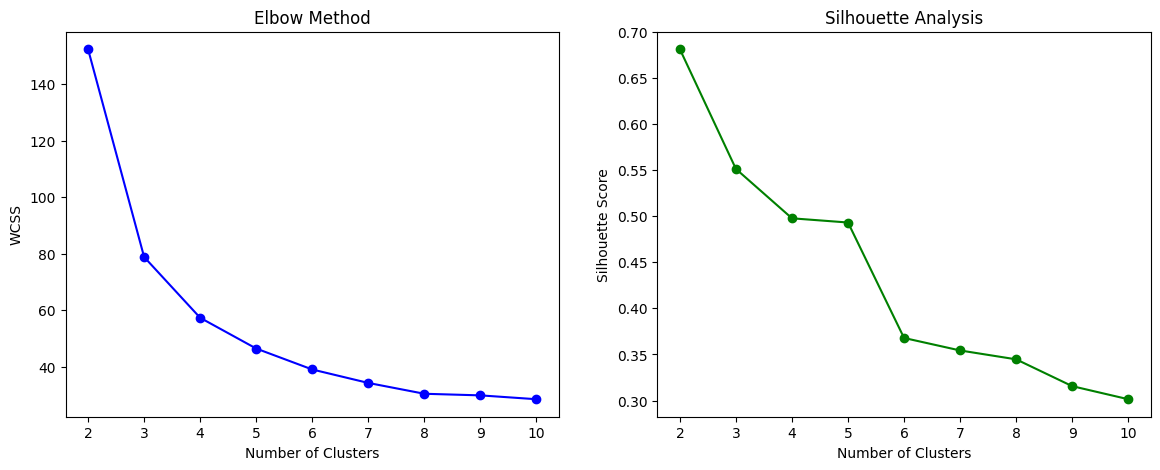

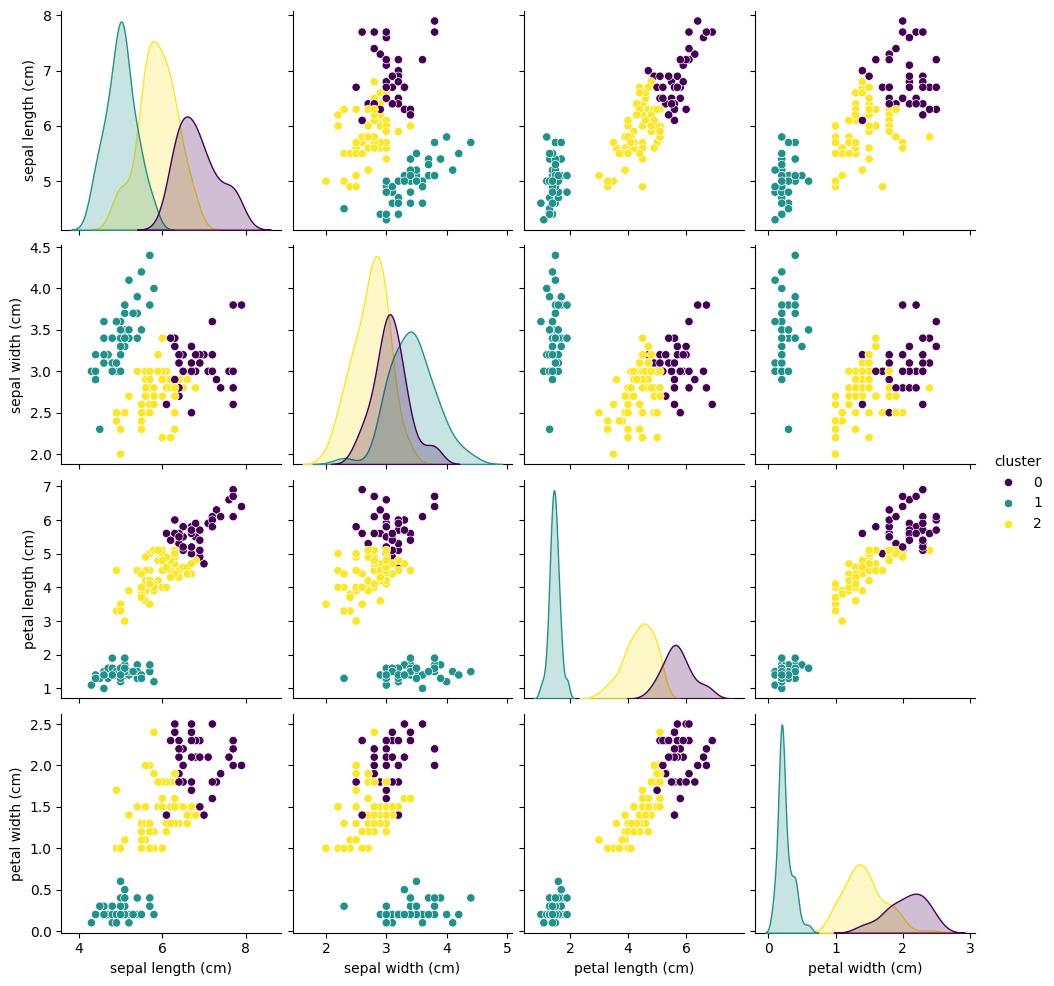

In [1]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import load_iris
from sklearn.metrics import silhouette_score
import pandas as pd
import seaborn as sns

data = load_iris()
X = pd.DataFrame(data.data, columns=data.feature_names)

wcss = []
silhouette_scores = []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    km.fit(X)
    wcss.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X, km.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(range(2, 11), wcss, marker='o', color='blue')
ax1.set_xlabel('Number of Clusters')
ax1.set_ylabel('WCSS')
ax1.set_title('Elbow Method')

ax2.plot(K_range, silhouette_scores, marker='o', color='green')
ax2.set_xlabel('Number of Clusters')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Analysis')
plt.show()

kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
X['cluster'] = kmeans.fit_predict(X)

sns.pairplot(X, hue='cluster', palette='viridis')
plt.show()

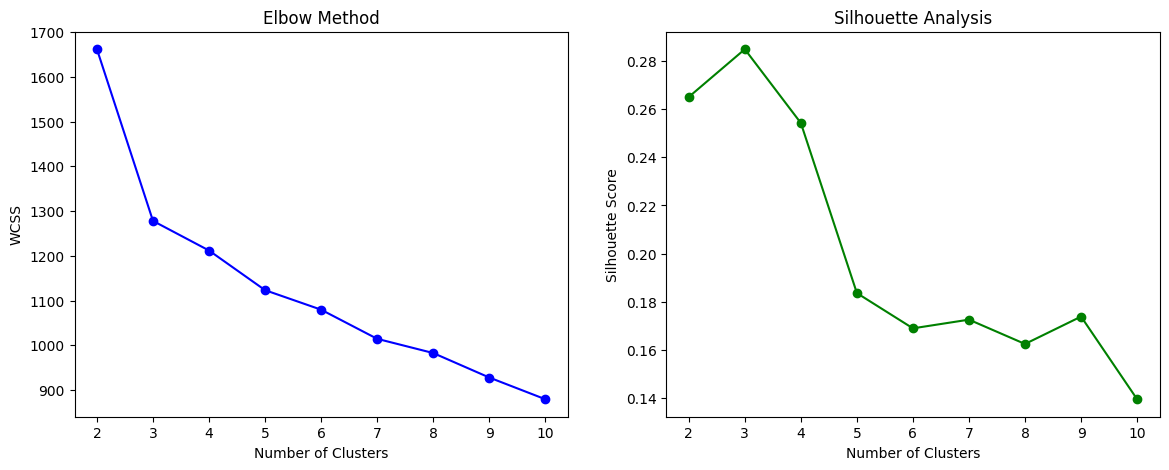

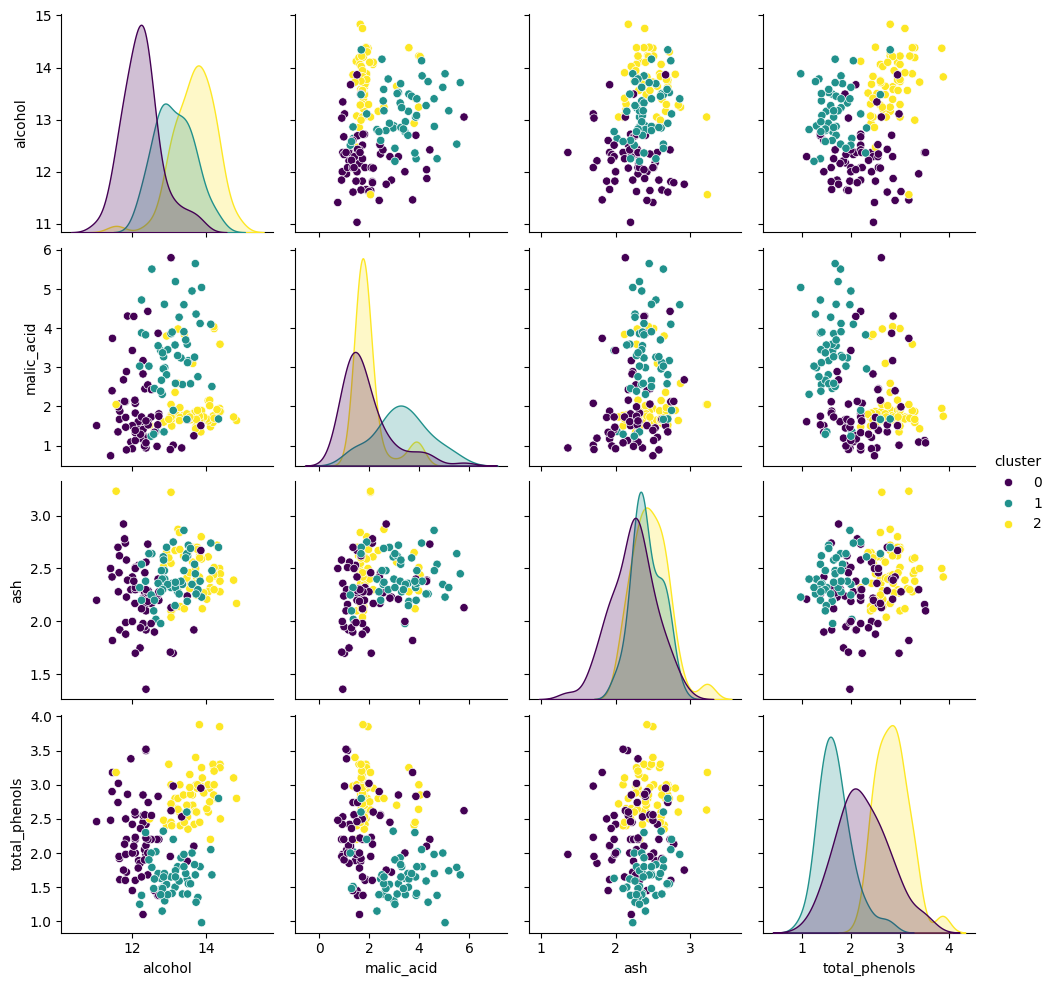

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import pandas as pd
import seaborn as sns

data = load_wine()
X = pd.DataFrame(data.data, columns=data.feature_names)
X_scaled = StandardScaler().fit_transform(X)

wcss = []
silhouette_scores = []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    km.fit(X_scaled)
    wcss.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, km.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(K_range, wcss, marker='o', color='blue')
ax1.set_xlabel('Number of Clusters')
ax1.set_ylabel('WCSS')
ax1.set_title('Elbow Method')

ax2.plot(K_range, silhouette_scores, marker='o', color='green')
ax2.set_xlabel('Number of Clusters')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Analysis')
plt.show()

kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
X['cluster'] = kmeans.fit_predict(X_scaled)

sns.pairplot(X[['alcohol', 'malic_acid', 'ash', 'total_phenols', 'cluster']], hue='cluster', palette='viridis')
plt.show()